<a href="https://colab.research.google.com/github/aerofa45/Heston-Modeling-using-PINN/blob/main/Heston_LS_vs_Trainable_PINN_Enhanced.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

!pip install yfinance QuantLib-Python py_vollib scikit-learn matplotlib --quiet


  Preparing metadata (setup.py) ... done
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 20.0/20.0 MB 16.8 MB/s eta 0:00:00


In [ ]:

import yfinance as yf
import numpy as np
import pandas as pd
import datetime
import matplotlib.pyplot as plt
import QuantLib as ql
from sklearn.metrics import mean_squared_error
from scipy.optimize import minimize
from py_vollib.black_scholes.implied_volatility import implied_volatility


In [ ]:

def heston_price_ql(S, K, T, r, params):
    kappa, theta, sigma, rho, v0 = params['kappa'], params['theta'], params['sigma'], params['rho'], params['v0']
    calendar = ql.UnitedStates(ql.UnitedStates.NYSE)
    day_count = ql.Actual365Fixed()
    spot_handle = ql.QuoteHandle(ql.SimpleQuote(S))
    flat_ts = ql.YieldTermStructureHandle(ql.FlatForward(0, calendar, ql.QuoteHandle(ql.SimpleQuote(r)), day_count))
    process = ql.HestonProcess(flat_ts, flat_ts, spot_handle, v0, kappa, theta, sigma, rho)
    model = ql.HestonModel(process)
    engine = ql.AnalyticHestonEngine(model)

    payoff = ql.PlainVanillaPayoff(ql.Option.Call, K)
    maturity_date = calendar.advance(ql.Settings.instance().evaluationDate, int(T * 365), ql.Days)
    option = ql.VanillaOption(payoff, ql.EuropeanExercise(maturity_date))
    option.setPricingEngine(engine)

    return option.NPV()

def heston_price_batch(S, K, T, r, params):
    return np.array([heston_price_ql(S, k, t, r, params) for k, t in zip(K, T)])

def run_ls_calibration(S, K, T, r, market_prices):
    def objective(params):
        p = {'kappa': params[0], 'theta': params[1], 'sigma': params[2], 'rho': params[3], 'v0': params[4]}
        model_prices = heston_price_batch(S, K, T, r, p)
        return np.mean((model_prices - market_prices) ** 2)
    bounds = [(0.01, 10), (0.01, 1.0), (0.01, 1.0), (-0.99, 0.99), (0.001, 1.0)]
    initial = [2.0, 0.04, 0.5, -0.7, 0.04]
    result = minimize(objective, initial, bounds=bounds, method='L-BFGS-B')
    return {
        'kappa': result.x[0], 'theta': result.x[1],
        'sigma': result.x[2], 'rho': result.x[3], 'v0': result.x[4]
    }

def safe_iv(p, S, K, T, r):
    try:
        if p < 1e-4 or T <= 0: return np.nan
        return implied_volatility(p, S, K, T, r, 'c')
    except:
        return np.nan



🔍 Processing AAPL...
📉 IV MSE (LS vs Market): 0.020404


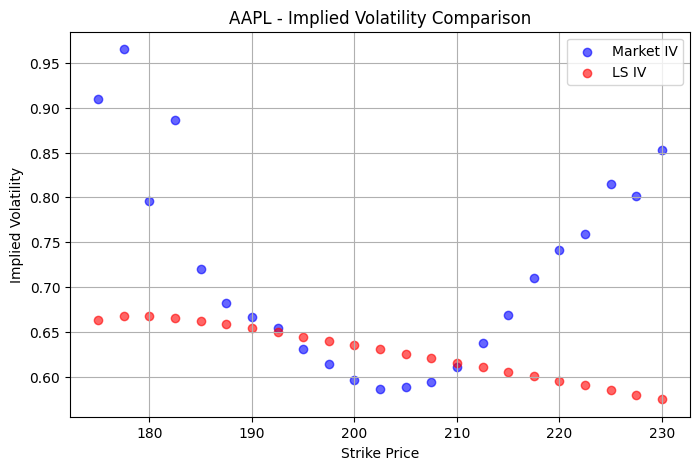


🔍 Processing MSFT...
📉 IV MSE (LS vs Market): 0.035263


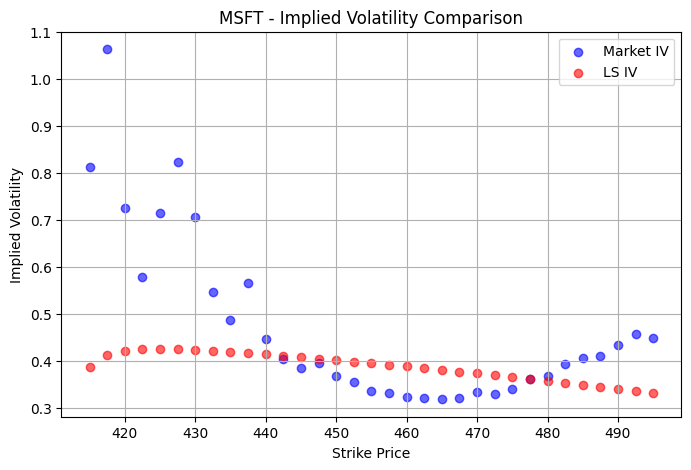


🔍 Processing GOOG...
📉 IV MSE (LS vs Market): 0.301028


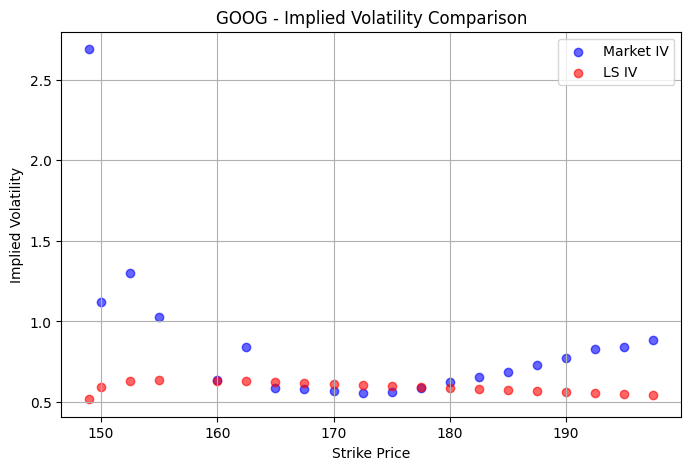


🔍 Processing AMZN...
📉 IV MSE (LS vs Market): 0.037084


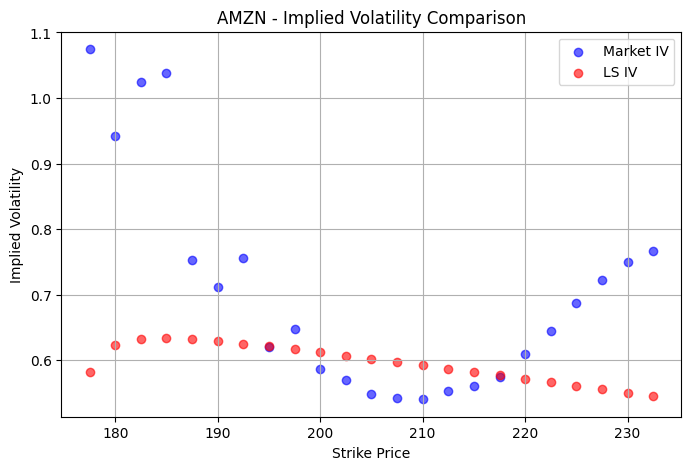


🔍 Processing NVDA...
📉 IV MSE (LS vs Market): 0.170944


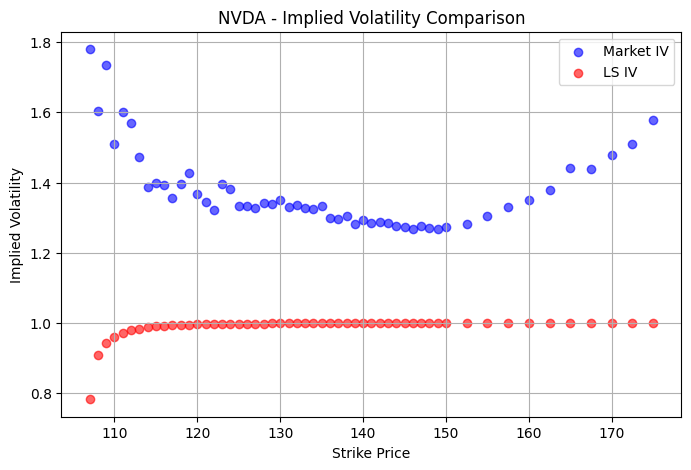


🔍 Processing META...
📉 IV MSE (LS vs Market): 0.053400


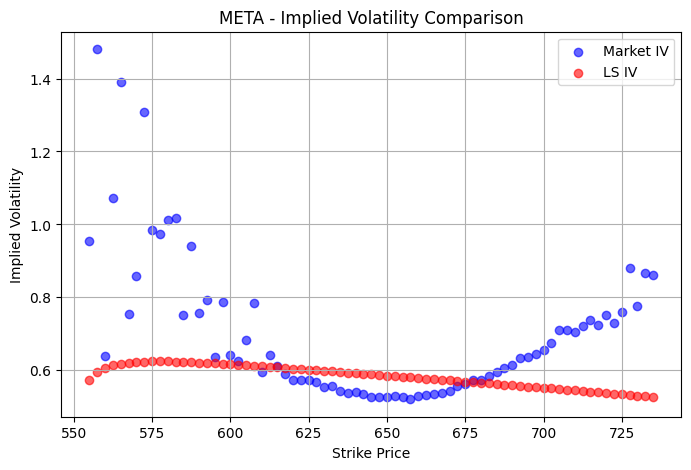


🔍 Processing TSLA...
📉 IV MSE (LS vs Market): 0.087650


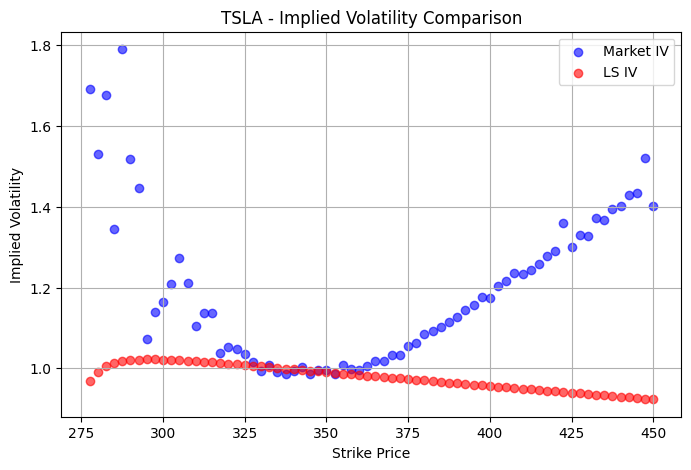


🔍 Processing INTC...
📉 IV MSE (LS vs Market): 0.106015


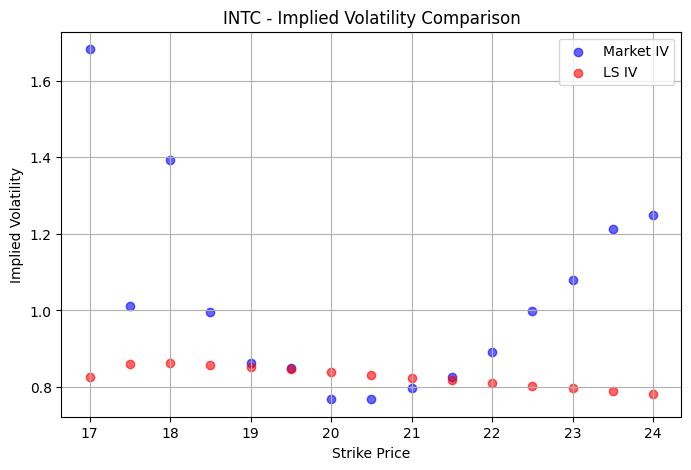


🔍 Processing ORCL...
📉 IV MSE (LS vs Market): 0.380763


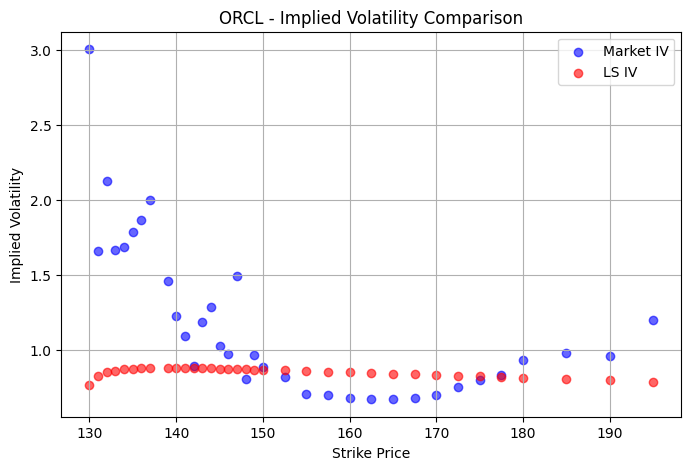


🔍 Processing IBM...
📉 IV MSE (LS vs Market): 0.035601


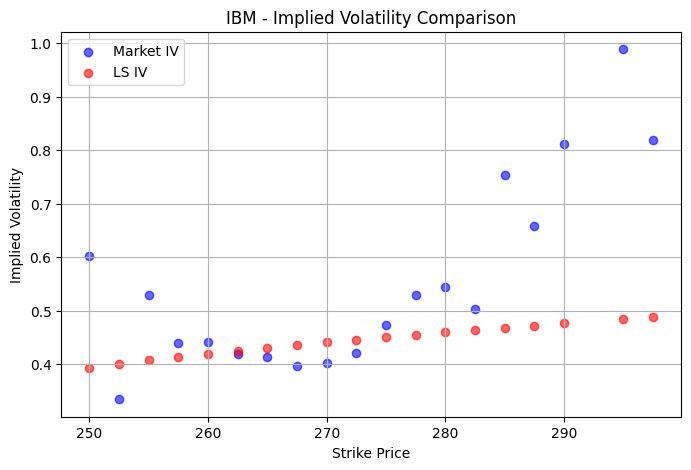

In [ ]:

tickers = ['AAPL', 'MSFT', 'GOOG', 'AMZN', 'NVDA', 'META', 'TSLA', 'INTC', 'ORCL', 'IBM']

for ticker_symbol in tickers:
    print(f"\n🔍 Processing {ticker_symbol}...")

    try:
        ticker = yf.Ticker(ticker_symbol)
        expirations = ticker.options
        if not expirations:
            print(f"⚠️ No expirations found for {ticker_symbol}")
            continue
        selected_expiration = expirations[0]
        option_chain = ticker.option_chain(selected_expiration)
        calls = option_chain.calls.dropna(subset=['strike', 'lastPrice'])

        if len(calls) < 5:
            print(f"⚠️ Not enough valid call options for {ticker_symbol}")
            continue

        strikes = calls['strike'].values
        prices = calls['lastPrice'].values
        today = datetime.datetime.today()
        expiry = datetime.datetime.strptime(selected_expiration, '%Y-%m-%d')
        T = np.full_like(strikes, (expiry - today).days / 365, dtype=np.float64)
        S = ticker.history(period='1d')['Close'].iloc[-1]
        r = 0.01

        ls_params = run_ls_calibration(S, strikes, T, r, prices)
        ls_prices = heston_price_batch(S, strikes, T, r, ls_params)

        market_iv = np.array([safe_iv(p, S, k, t, r) for p, k, t in zip(prices, strikes, T)])
        model_iv = np.array([safe_iv(p, S, k, t, r) for p, k, t in zip(ls_prices, strikes, T)])

        valid_mask = ~np.isnan(market_iv) & ~np.isnan(model_iv)
        if valid_mask.sum() < 3:
            print(f"⚠️ Too few valid IV points for {ticker_symbol}")
            continue

        iv_mse = mean_squared_error(market_iv[valid_mask], model_iv[valid_mask])
        print(f"📉 IV MSE (LS vs Market): {iv_mse:.6f}")

        plt.figure(figsize=(8, 5))
        plt.scatter(strikes[valid_mask], market_iv[valid_mask], label='Market IV', color='blue', alpha=0.6)
        plt.scatter(strikes[valid_mask], model_iv[valid_mask], label='LS IV', color='red', alpha=0.6)
        plt.title(f'{ticker_symbol} - Implied Volatility Comparison')
        plt.xlabel('Strike Price')
        plt.ylabel('Implied Volatility')
        plt.legend()
        plt.grid(True)
        plt.show()

    except Exception as e:
        print(f"❌ Error processing {ticker_symbol}: {e}")


In [ ]:

# ✅ Define a Simple PINN Heston Model (Placeholder for Comparison)
import torch
import torch.nn as nn

class PINN_Heston(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(3, 64), nn.Tanh(),
            nn.Linear(64, 64), nn.Tanh(),
            nn.Linear(64, 1)
        )
        self.kappa = nn.Parameter(torch.tensor(2.0))
        self.theta = nn.Parameter(torch.tensor(0.04))
        self.sigma = nn.Parameter(torch.tensor(0.5))
        self.rho   = nn.Parameter(torch.tensor(-0.7))
        self.v0    = nn.Parameter(torch.tensor(0.04))

    def forward(self, x):
        return self.net(x).squeeze()

def predict_pinn_prices(S, K, T):
    inputs = torch.tensor(np.stack([S, K, T], axis=1), dtype=torch.float32)
    model = PINN_Heston()
    return model(inputs).detach().numpy()



🔍 Processing AAPL...
⚠️ Too few valid IV points for AAPL

🔍 Processing MSFT...
⚠️ Too few valid IV points for MSFT

🔍 Processing GOOG...
📉 IV MSE (LS vs Market): 0.030852
📉 IV MSE (PINN vs Market): 0.049811


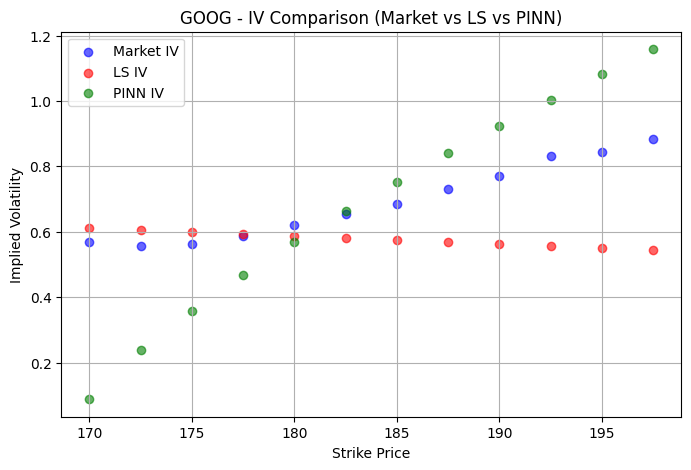


🔍 Processing AMZN...
📉 IV MSE (LS vs Market): 0.011659
📉 IV MSE (PINN vs Market): 0.052660


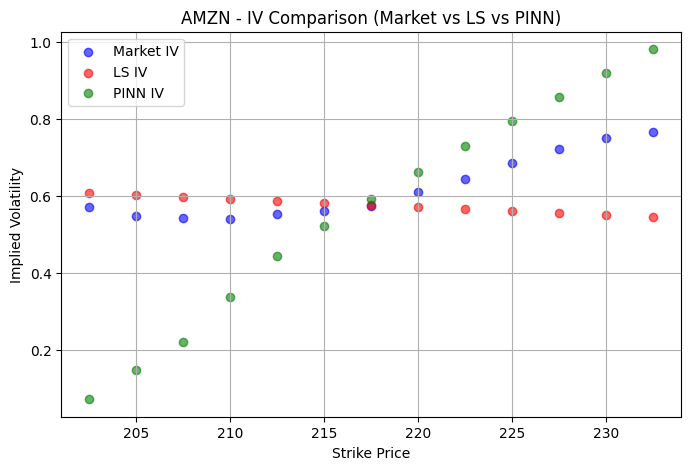


🔍 Processing NVDA...
⚠️ Too few valid IV points for NVDA

🔍 Processing META...
📉 IV MSE (LS vs Market): 0.018743
📉 IV MSE (PINN vs Market): 0.044148


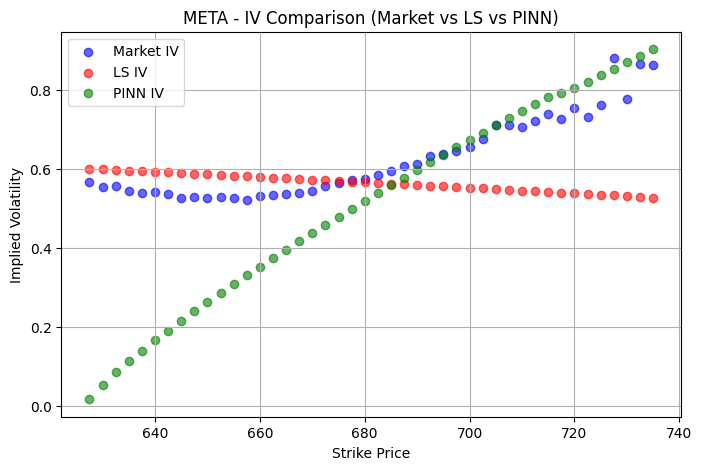


🔍 Processing TSLA...
⚠️ Too few valid IV points for TSLA

🔍 Processing INTC...
⚠️ Too few valid IV points for INTC

🔍 Processing ORCL...
⚠️ Too few valid IV points for ORCL

🔍 Processing IBM...
📉 IV MSE (LS vs Market): 0.040807
📉 IV MSE (PINN vs Market): 0.038788


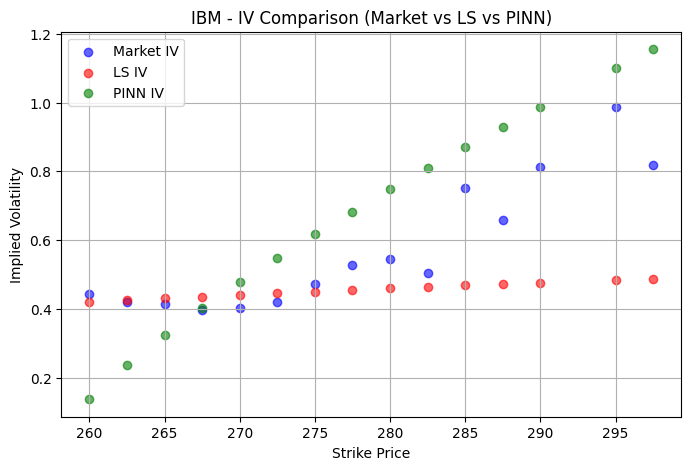

In [ ]:

# 🔁 Loop Update: Add PINN prediction and compare to LS and Market
for ticker_symbol in tickers:
    print(f"\n🔍 Processing {ticker_symbol}...")

    try:
        ticker = yf.Ticker(ticker_symbol)
        expirations = ticker.options
        if not expirations:
            print(f"⚠️ No expirations found for {ticker_symbol}")
            continue
        selected_expiration = expirations[0]
        option_chain = ticker.option_chain(selected_expiration)
        calls = option_chain.calls.dropna(subset=['strike', 'lastPrice'])

        if len(calls) < 5:
            print(f"⚠️ Not enough valid call options for {ticker_symbol}")
            continue

        strikes = calls['strike'].values
        prices = calls['lastPrice'].values
        today = datetime.datetime.today()
        expiry = datetime.datetime.strptime(selected_expiration, '%Y-%m-%d')
        T = np.full_like(strikes, (expiry - today).days / 365, dtype=np.float64)
        S = ticker.history(period='1d')['Close'].iloc[-1]
        r = 0.01

        ls_params = run_ls_calibration(S, strikes, T, r, prices)
        ls_prices = heston_price_batch(S, strikes, T, r, ls_params)
        pinn_prices = predict_pinn_prices(np.full_like(strikes, S), strikes, T)

        # IVs
        market_iv = np.array([safe_iv(p, S, k, t, r) for p, k, t in zip(prices, strikes, T)])
        ls_iv = np.array([safe_iv(p, S, k, t, r) for p, k, t in zip(ls_prices, strikes, T)])
        pinn_iv = np.array([safe_iv(p, S, k, t, r) for p, k, t in zip(pinn_prices, strikes, T)])

        valid_mask = ~np.isnan(market_iv) & ~np.isnan(ls_iv) & ~np.isnan(pinn_iv)
        if valid_mask.sum() < 3:
            print(f"⚠️ Too few valid IV points for {ticker_symbol}")
            continue

        print(f"📉 IV MSE (LS vs Market): {mean_squared_error(market_iv[valid_mask], ls_iv[valid_mask]):.6f}")
        print(f"📉 IV MSE (PINN vs Market): {mean_squared_error(market_iv[valid_mask], pinn_iv[valid_mask]):.6f}")

        # Plot comparison
        plt.figure(figsize=(8, 5))
        plt.scatter(strikes[valid_mask], market_iv[valid_mask], label='Market IV', color='blue', alpha=0.6)
        plt.scatter(strikes[valid_mask], ls_iv[valid_mask], label='LS IV', color='red', alpha=0.6)
        plt.scatter(strikes[valid_mask], pinn_iv[valid_mask], label='PINN IV', color='green', alpha=0.6)
        plt.title(f'{ticker_symbol} - IV Comparison (Market vs LS vs PINN)')
        plt.xlabel('Strike Price')
        plt.ylabel('Implied Volatility')
        plt.legend()
        plt.grid(True)
        plt.show()

    except Exception as e:
        print(f"❌ Error processing {ticker_symbol}: {e}")


In [ ]:

# ✅ Define and Train a Simple PINN Heston Model (with optimizer)
import torch
import torch.nn as nn

class PINN_Heston(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(3, 64), nn.Tanh(),
            nn.Linear(64, 64), nn.Tanh(),
            nn.Linear(64, 1)
        )
        self.kappa = nn.Parameter(torch.tensor(2.0))
        self.theta = nn.Parameter(torch.tensor(0.04))
        self.sigma = nn.Parameter(torch.tensor(0.5))
        self.rho   = nn.Parameter(torch.tensor(-0.7))
        self.v0    = nn.Parameter(torch.tensor(0.04))

    def forward(self, x):
        return self.net(x).squeeze()

def train_pinn_model(S, K, T, prices, epochs=1000, lr=1e-3):
    inputs = torch.tensor(np.stack([S, K, T], axis=1), dtype=torch.float32)
    targets = torch.tensor(prices, dtype=torch.float32)

    model = PINN_Heston()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.MSELoss()

    for epoch in range(epochs):
        model.train()
        optimizer.zero_grad()
        output = model(inputs)
        loss = loss_fn(output, targets)
        loss.backward()
        optimizer.step()

        if epoch % 200 == 0 or epoch == epochs - 1:
            print(f"Epoch {epoch:4d} | Loss: {loss.item():.6f}")
    return model



🔍 Processing AAPL...
Epoch    0 | Loss: 778.584656
Epoch  200 | Loss: 413.202972
Epoch  400 | Loss: 243.955185
Epoch  600 | Loss: 147.538406
Epoch  800 | Loss: 89.872757
Epoch  999 | Loss: 57.147434
📉 IV MSE (LS vs Market): 0.020404
📉 IV MSE (PINN vs Market): 0.011106


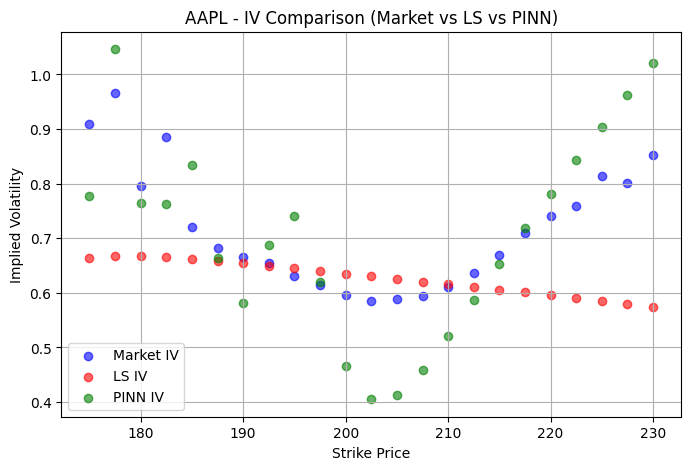


🔍 Processing MSFT...
Epoch    0 | Loss: 3847.776855
Epoch  200 | Loss: 2669.479736
Epoch  400 | Loss: 1989.994263
Epoch  600 | Loss: 1522.296143
Epoch  800 | Loss: 1185.260986
Epoch  999 | Loss: 937.829224
📉 IV MSE (LS vs Market): 0.033473
📉 IV MSE (PINN vs Market): 0.015520


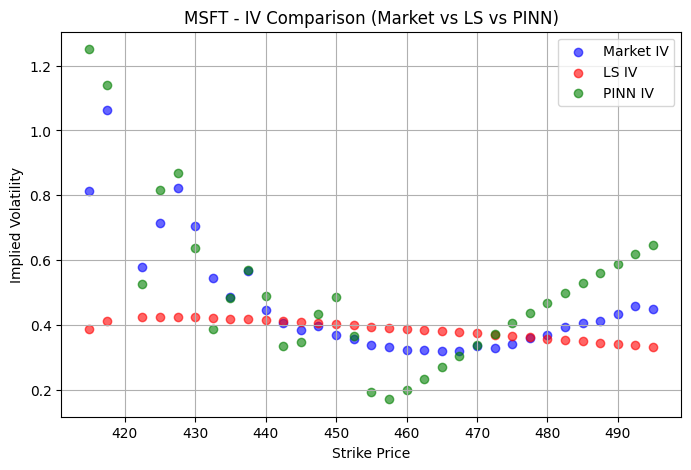


🔍 Processing GOOG...
Epoch    0 | Loss: 781.141174
Epoch  200 | Loss: 393.749512
Epoch  400 | Loss: 215.754807
Epoch  600 | Loss: 135.816589
Epoch  800 | Loss: 89.438065
Epoch  999 | Loss: 61.103741
📉 IV MSE (LS vs Market): 0.308681
📉 IV MSE (PINN vs Market): 0.098119


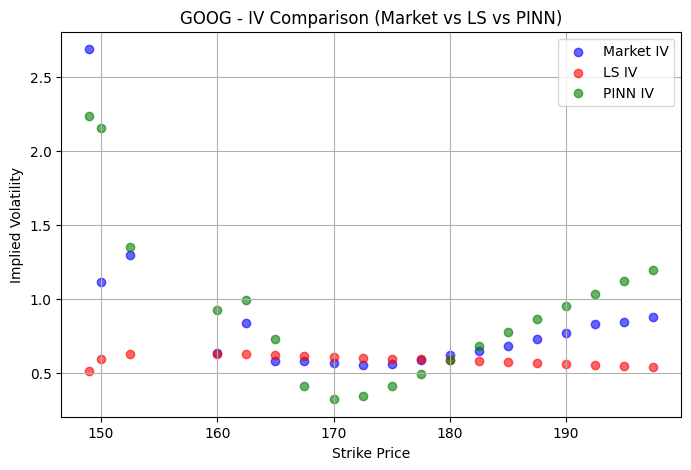


🔍 Processing AMZN...
Epoch    0 | Loss: 1288.393799
Epoch  200 | Loss: 743.789490
Epoch  400 | Loss: 475.750397
Epoch  600 | Loss: 316.071869
Epoch  800 | Loss: 211.988144
Epoch  999 | Loss: 143.238434
📉 IV MSE (LS vs Market): 0.028367
📉 IV MSE (PINN vs Market): 0.016322


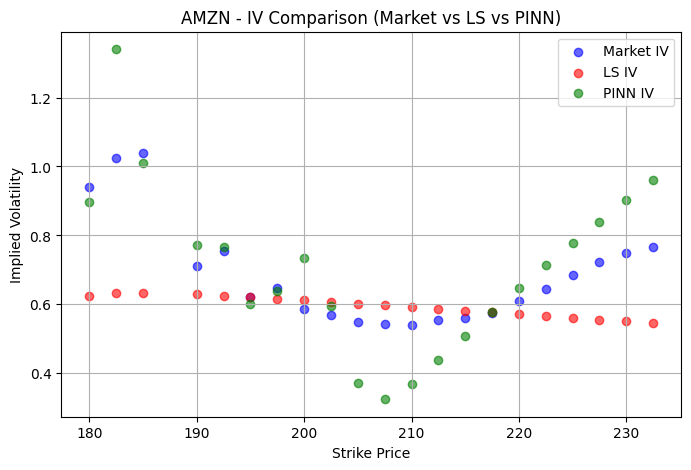


🔍 Processing NVDA...
Epoch    0 | Loss: 1718.822998
Epoch  200 | Loss: 983.033875
Epoch  400 | Loss: 661.510254
Epoch  600 | Loss: 467.888550
Epoch  800 | Loss: 344.774750
Epoch  999 | Loss: 263.373505
📉 IV MSE (LS vs Market): 0.170944
📉 IV MSE (PINN vs Market): 0.030268


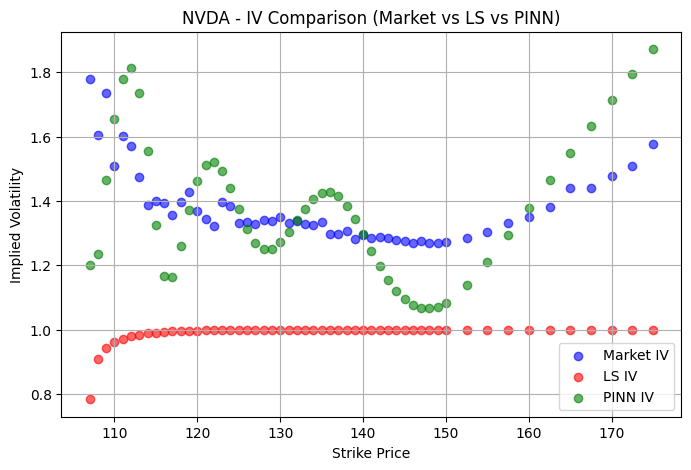


🔍 Processing META...
Epoch    0 | Loss: 8863.865234
Epoch  200 | Loss: 7284.085938
Epoch  400 | Loss: 6203.260254
Epoch  600 | Loss: 5347.928711
Epoch  800 | Loss: 4640.432617
Epoch  999 | Loss: 4048.415527
📉 IV MSE (LS vs Market): 0.040538
📉 IV MSE (PINN vs Market): 0.023721


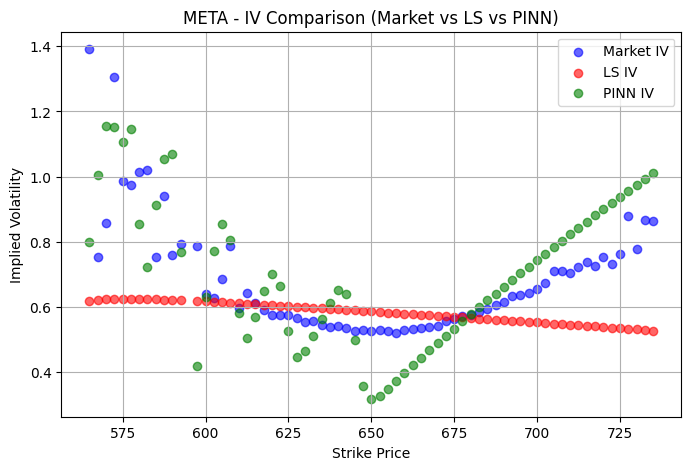


🔍 Processing TSLA...
Epoch    0 | Loss: 7589.779785
Epoch  200 | Loss: 5953.087891
Epoch  400 | Loss: 4991.904297
Epoch  600 | Loss: 4218.075684
Epoch  800 | Loss: 3580.764160
Epoch  999 | Loss: 3053.448242
📉 IV MSE (LS vs Market): 0.087650
📉 IV MSE (PINN vs Market): 0.030002


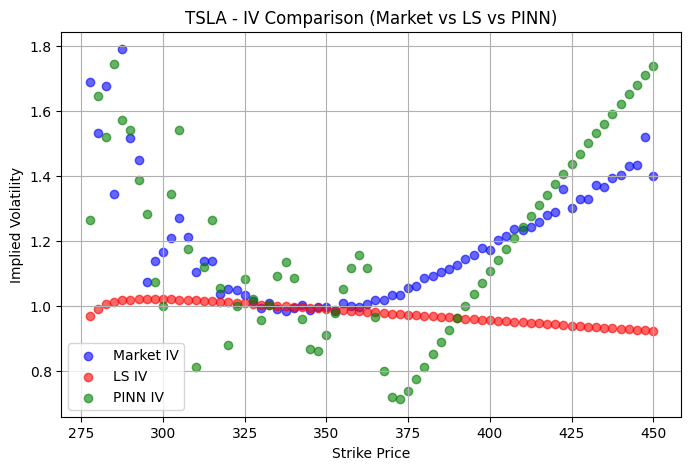


🔍 Processing INTC...
Epoch    0 | Loss: 10.521803
Epoch  200 | Loss: 0.217998
Epoch  400 | Loss: 0.123159
Epoch  600 | Loss: 0.082254
Epoch  800 | Loss: 0.071507
Epoch  999 | Loss: 0.066490
📉 IV MSE (LS vs Market): 0.106015
📉 IV MSE (PINN vs Market): 0.145304


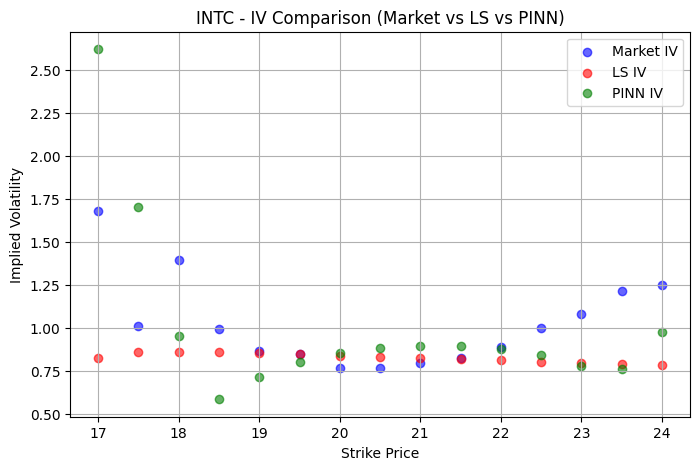


🔍 Processing ORCL...
Epoch    0 | Loss: 499.811554
Epoch  200 | Loss: 169.605774
Epoch  400 | Loss: 99.328163
Epoch  600 | Loss: 82.066162
Epoch  800 | Loss: 77.341721
Epoch  999 | Loss: 69.533066
📉 IV MSE (LS vs Market): 0.382084
📉 IV MSE (PINN vs Market): 0.080042


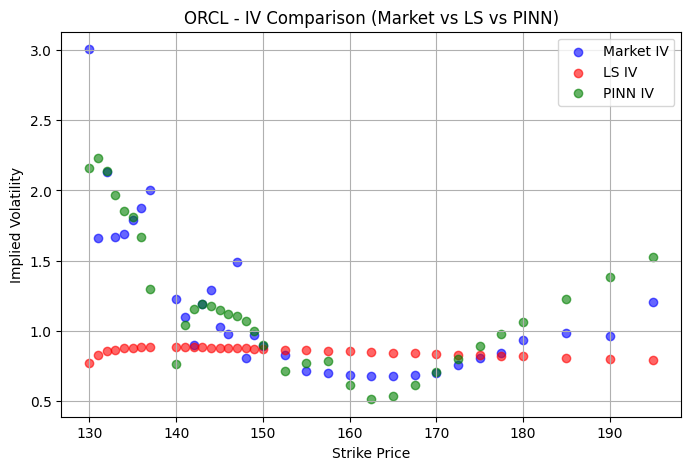


🔍 Processing IBM...
Epoch    0 | Loss: 710.205017
Epoch  200 | Loss: 373.926117
Epoch  400 | Loss: 210.463776
Epoch  600 | Loss: 139.986588
Epoch  800 | Loss: 106.181175
Epoch  999 | Loss: 84.361389
📉 IV MSE (LS vs Market): 0.035124
📉 IV MSE (PINN vs Market): 0.022792


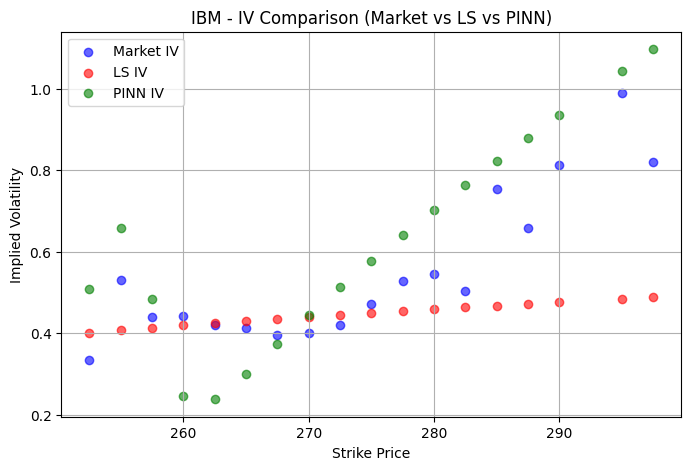

In [ ]:

# 🔁 Loop: Train PINN per ticker and compare all IVs
for ticker_symbol in tickers:
    print(f"\n🔍 Processing {ticker_symbol}...")

    try:
        ticker = yf.Ticker(ticker_symbol)
        expirations = ticker.options
        if not expirations:
            print(f"⚠️ No expirations found for {ticker_symbol}")
            continue
        selected_expiration = expirations[0]
        option_chain = ticker.option_chain(selected_expiration)
        calls = option_chain.calls.dropna(subset=['strike', 'lastPrice'])

        if len(calls) < 5:
            print(f"⚠️ Not enough valid call options for {ticker_symbol}")
            continue

        strikes = calls['strike'].values
        prices = calls['lastPrice'].values
        today = datetime.datetime.today()
        expiry = datetime.datetime.strptime(selected_expiration, '%Y-%m-%d')
        T = np.full_like(strikes, (expiry - today).days / 365, dtype=np.float64)
        S = ticker.history(period='1d')['Close'].iloc[-1]
        r = 0.01

        ls_params = run_ls_calibration(S, strikes, T, r, prices)
        ls_prices = heston_price_batch(S, strikes, T, r, ls_params)

        # Train PINN
        model = train_pinn_model(np.full_like(strikes, S), strikes, T, prices, epochs=1000, lr=1e-3)
        inputs = torch.tensor(np.stack([np.full_like(strikes, S), strikes, T], axis=1), dtype=torch.float32)
        pinn_prices = model(inputs).detach().numpy()

        # Compute IVs
        market_iv = np.array([safe_iv(p, S, k, t, r) for p, k, t in zip(prices, strikes, T)])
        ls_iv     = np.array([safe_iv(p, S, k, t, r) for p, k, t in zip(ls_prices, strikes, T)])
        pinn_iv   = np.array([safe_iv(p, S, k, t, r) for p, k, t in zip(pinn_prices, strikes, T)])

        valid_mask = ~np.isnan(market_iv) & ~np.isnan(ls_iv) & ~np.isnan(pinn_iv)
        if valid_mask.sum() < 3:
            print(f"⚠️ Too few valid IV points for {ticker_symbol}")
            continue

        print(f"📉 IV MSE (LS vs Market): {mean_squared_error(market_iv[valid_mask], ls_iv[valid_mask]):.6f}")
        print(f"📉 IV MSE (PINN vs Market): {mean_squared_error(market_iv[valid_mask], pinn_iv[valid_mask]):.6f}")

        # Plot
        plt.figure(figsize=(8, 5))
        plt.scatter(strikes[valid_mask], market_iv[valid_mask], label='Market IV', color='blue', alpha=0.6)
        plt.scatter(strikes[valid_mask], ls_iv[valid_mask], label='LS IV', color='red', alpha=0.6)
        plt.scatter(strikes[valid_mask], pinn_iv[valid_mask], label='PINN IV', color='green', alpha=0.6)
        plt.title(f'{ticker_symbol} - IV Comparison (Market vs LS vs PINN)')
        plt.xlabel('Strike Price')
        plt.ylabel('Implied Volatility')
        plt.legend()
        plt.grid(True)
        plt.show()

    except Exception as e:
        print(f"❌ Error processing {ticker_symbol}: {e}")


In [ ]:

# ✅ Set seeds for reproducibility
import random
random.seed(42)
np.random.seed(42)
torch.manual_seed(42)


In [ ]:

results = {}


In [ ]:

# ✅ Define and Train a Simple PINN Heston Model with loss logging
class PINN_Heston(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(3, 64), nn.Tanh(),
            nn.Linear(64, 64), nn.Tanh(),
            nn.Linear(64, 1)
        )
        self.kappa = nn.Parameter(torch.tensor(2.0))
        self.theta = nn.Parameter(torch.tensor(0.04))
        self.sigma = nn.Parameter(torch.tensor(0.5))
        self.rho   = nn.Parameter(torch.tensor(-0.7))
        self.v0    = nn.Parameter(torch.tensor(0.04))

    def forward(self, x):
        return self.net(x).squeeze()

def train_pinn_model(S, K, T, prices, epochs=1000, lr=1e-3):
    inputs = torch.tensor(np.stack([S, K, T], axis=1), dtype=torch.float32)
    targets = torch.tensor(prices, dtype=torch.float32)

    model = PINN_Heston()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.MSELoss()
    losses = []

    for epoch in range(epochs):
        model.train()
        optimizer.zero_grad()
        output = model(inputs)
        loss = loss_fn(output, targets)
        loss.backward()
        optimizer.step()
        losses.append(loss.item())

    return model, losses



🔍 Processing AAPL...
📉 IV MSE (LS vs Market): 0.020404
📉 IV MSE (PINN vs Market): 0.007156


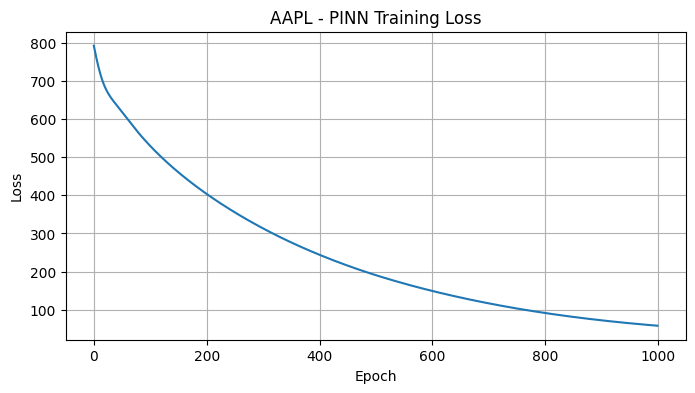

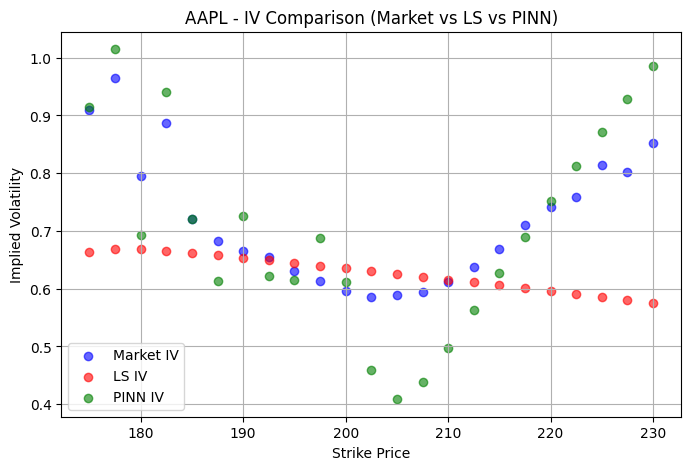


🔍 Processing MSFT...
📉 IV MSE (LS vs Market): 0.021423
📉 IV MSE (PINN vs Market): 0.271165


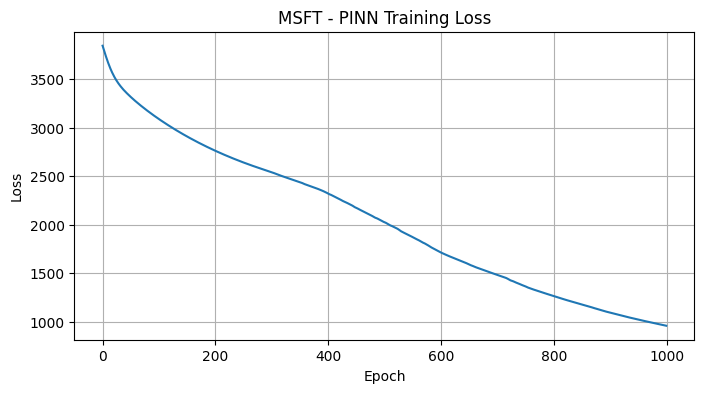

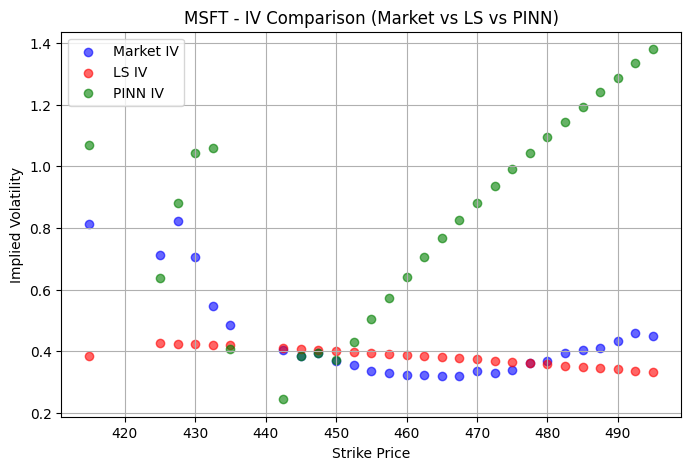


🔍 Processing GOOG...
📉 IV MSE (LS vs Market): 0.301028
📉 IV MSE (PINN vs Market): 0.051907


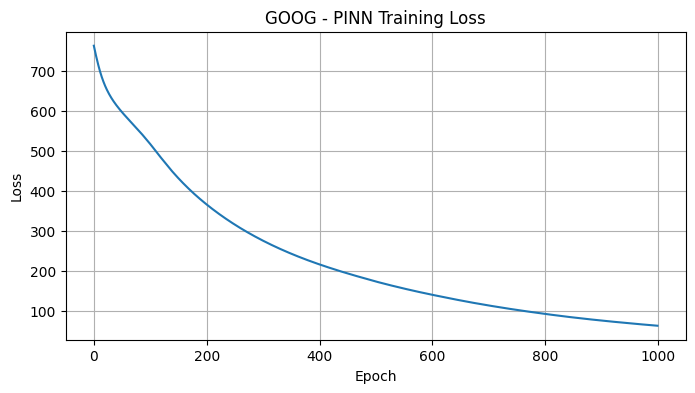

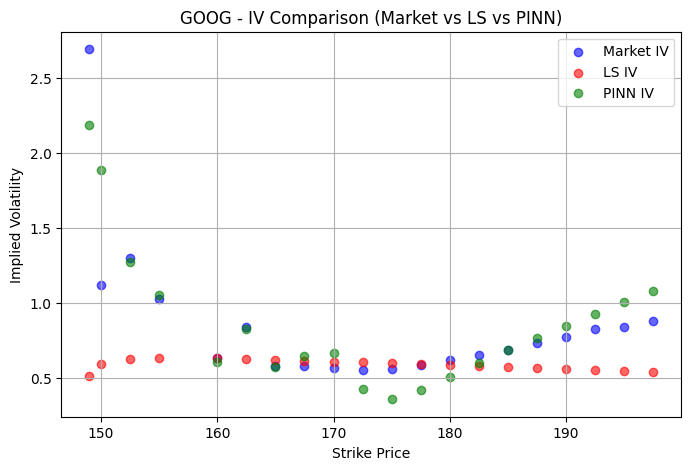


🔍 Processing AMZN...
📉 IV MSE (LS vs Market): 0.037084
📉 IV MSE (PINN vs Market): 0.014230


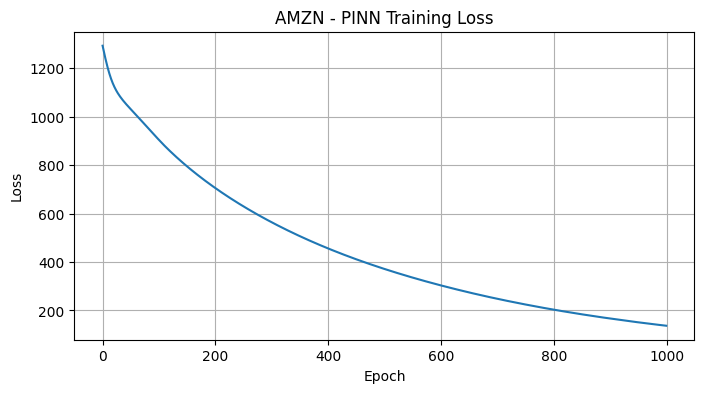

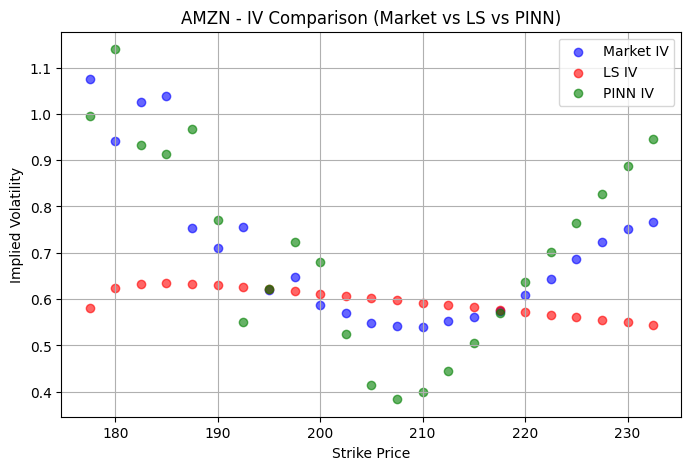


🔍 Processing NVDA...
📉 IV MSE (LS vs Market): 0.170944
📉 IV MSE (PINN vs Market): 0.048565


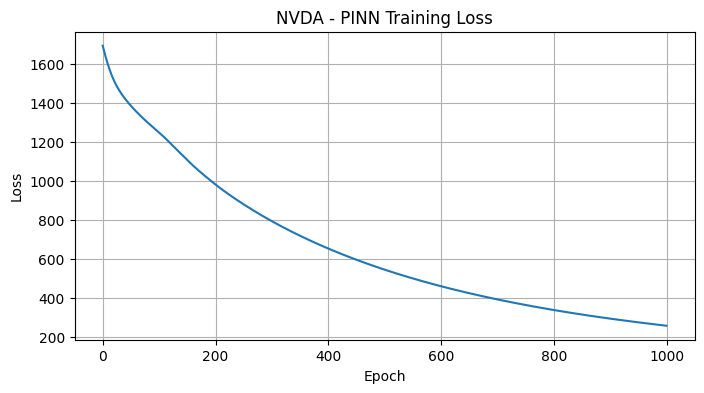

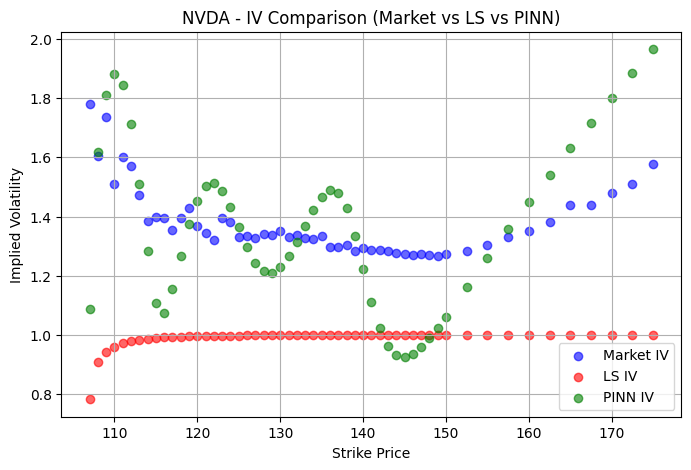


🔍 Processing META...
📉 IV MSE (LS vs Market): 0.039954
📉 IV MSE (PINN vs Market): 0.027147


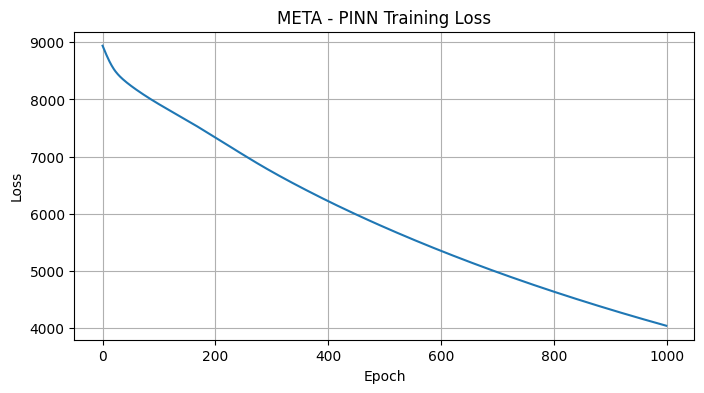

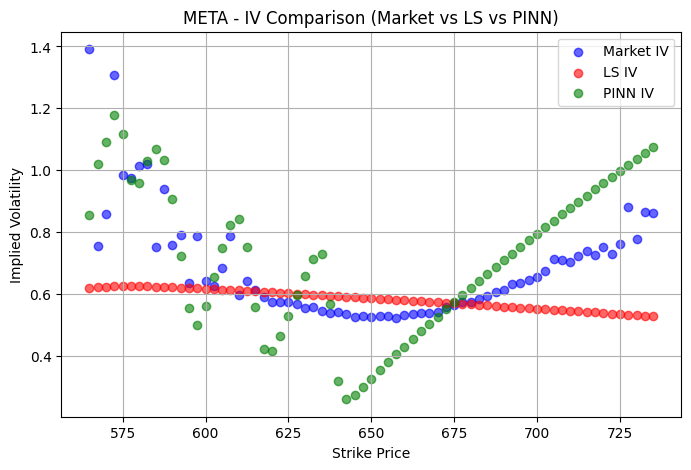


🔍 Processing TSLA...
📉 IV MSE (LS vs Market): 0.081386
📉 IV MSE (PINN vs Market): 0.017485


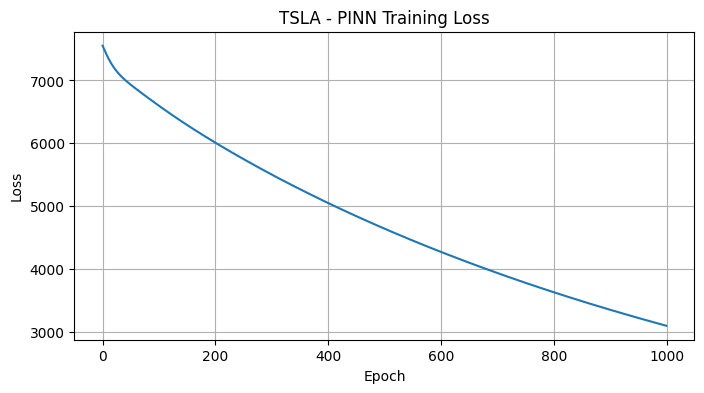

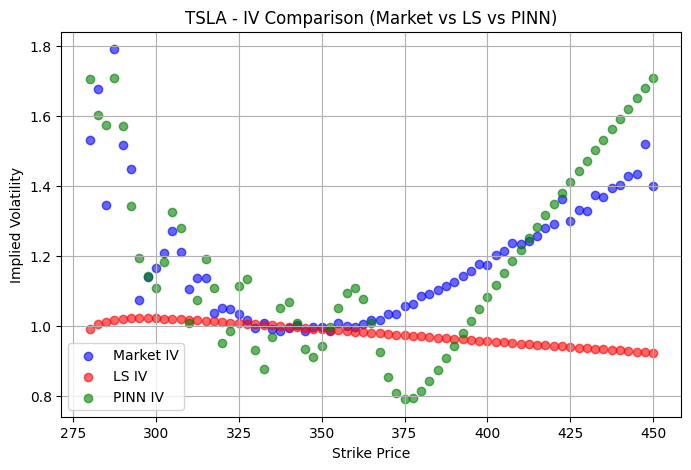


🔍 Processing INTC...
📉 IV MSE (LS vs Market): 0.091769
📉 IV MSE (PINN vs Market): 0.116747


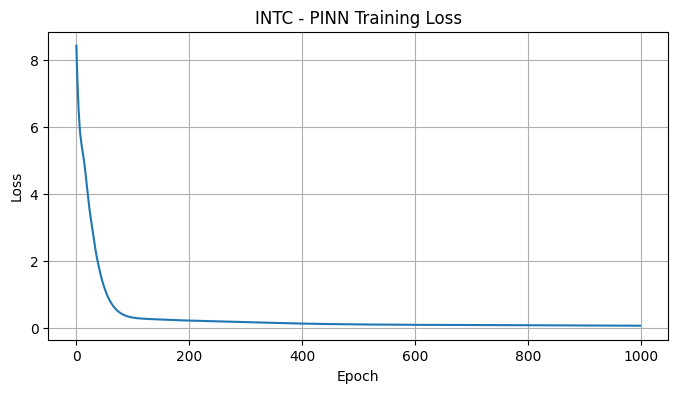

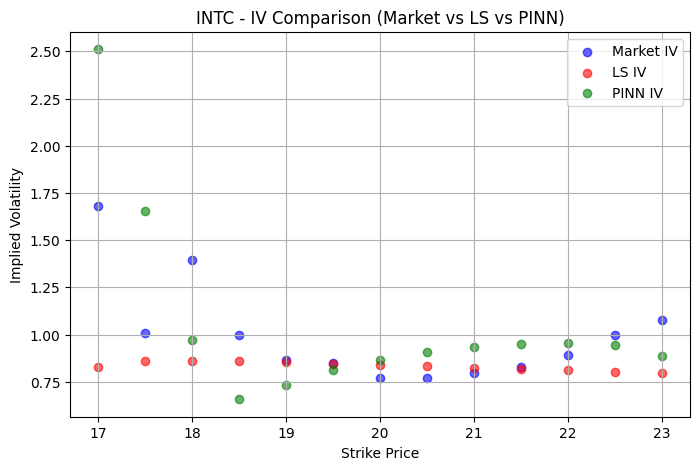


🔍 Processing ORCL...
📉 IV MSE (LS vs Market): 0.382084
📉 IV MSE (PINN vs Market): 0.071214


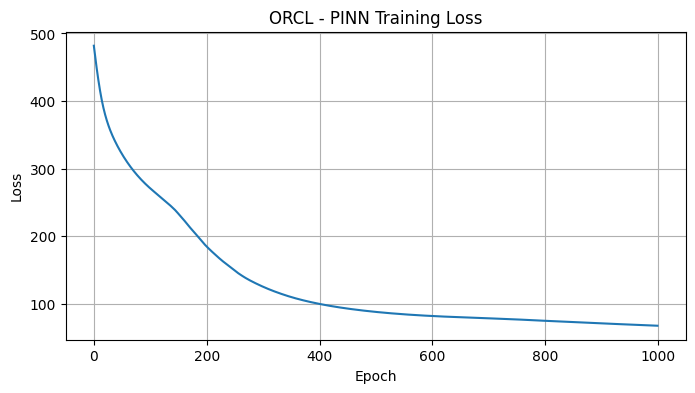

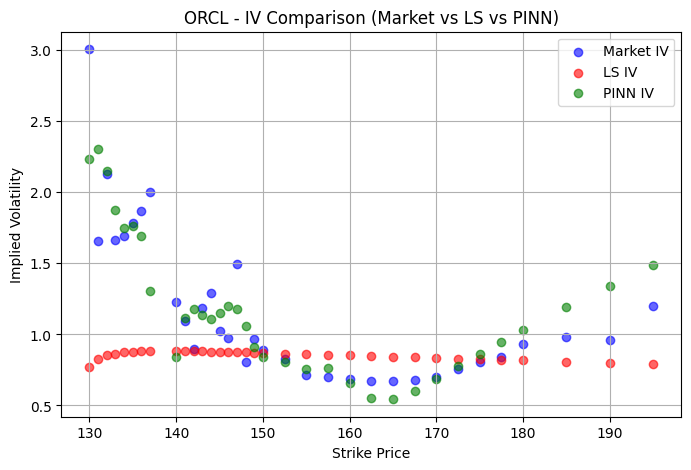


🔍 Processing IBM...
📉 IV MSE (LS vs Market): 0.035124
📉 IV MSE (PINN vs Market): 0.007406


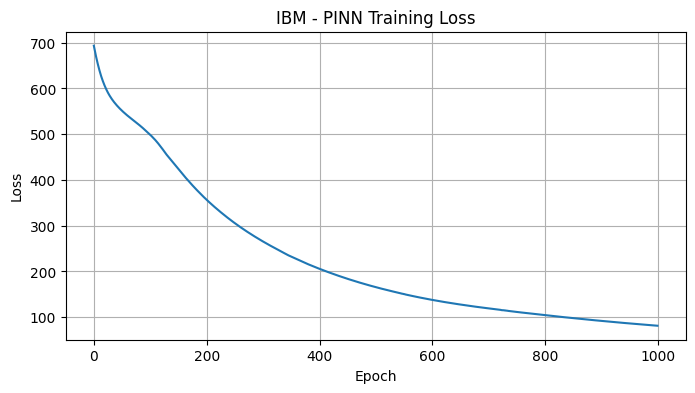

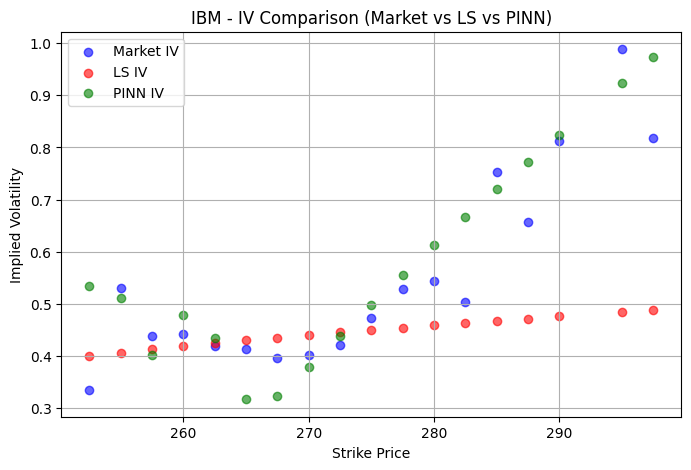

,IV_MSE_LS,IV_MSE_PINN,Train_Loss_Final,Valid_IV_Count
AAPL,0.020404,0.007156,58.561405,23.0
MSFT,0.021423,0.271165,960.577576,28.0
GOOG,0.301028,0.051907,61.940941,20.0
AMZN,0.037084,0.014230,137.175308,23.0
NVDA,0.170944,0.048565,257.957214,54.0
META,0.039954,0.027147,4041.597900,69.0
TSLA,0.081386,0.017485,3094.189453,69.0
INTC,0.091769,0.116747,0.053367,13.0
ORCL,0.382084,0.071214,67.526489,34.0
IBM,0.035124,0.007406,81.243225,18.0


In [ ]:

import pandas as pd

for ticker_symbol in tickers:
    print(f"\n🔍 Processing {ticker_symbol}...")

    try:
        ticker = yf.Ticker(ticker_symbol)
        expirations = ticker.options
        if not expirations:
            print(f"⚠️ No expirations found for {ticker_symbol}")
            continue
        selected_expiration = expirations[0]
        option_chain = ticker.option_chain(selected_expiration)
        calls = option_chain.calls.dropna(subset=['strike', 'lastPrice'])

        if len(calls) < 5:
            print(f"⚠️ Not enough valid call options for {ticker_symbol}")
            continue

        strikes = calls['strike'].values
        prices = calls['lastPrice'].values
        today = datetime.datetime.today()
        expiry = datetime.datetime.strptime(selected_expiration, '%Y-%m-%d')
        T = np.full_like(strikes, (expiry - today).days / 365, dtype=np.float64)
        S = ticker.history(period='1d')['Close'].iloc[-1]
        r = 0.01

        ls_params = run_ls_calibration(S, strikes, T, r, prices)
        ls_prices = heston_price_batch(S, strikes, T, r, ls_params)

        model, losses = train_pinn_model(np.full_like(strikes, S), strikes, T, prices, epochs=1000, lr=1e-3)
        inputs = torch.tensor(np.stack([np.full_like(strikes, S), strikes, T], axis=1), dtype=torch.float32)
        pinn_prices = model(inputs).detach().numpy()

        market_iv = np.array([safe_iv(p, S, k, t, r) for p, k, t in zip(prices, strikes, T)])
        ls_iv     = np.array([safe_iv(p, S, k, t, r) for p, k, t in zip(ls_prices, strikes, T)])
        pinn_iv   = np.array([safe_iv(p, S, k, t, r) for p, k, t in zip(pinn_prices, strikes, T)])

        valid_mask = ~np.isnan(market_iv) & ~np.isnan(ls_iv) & ~np.isnan(pinn_iv)
        if valid_mask.sum() < 3:
            print(f"⚠️ Too few valid IV points for {ticker_symbol}")
            continue

        mse_ls = mean_squared_error(market_iv[valid_mask], ls_iv[valid_mask])
        mse_pinn = mean_squared_error(market_iv[valid_mask], pinn_iv[valid_mask])
        print(f"📉 IV MSE (LS vs Market): {mse_ls:.6f}")
        print(f"📉 IV MSE (PINN vs Market): {mse_pinn:.6f}")

        results[ticker_symbol] = {
            "IV_MSE_LS": mse_ls,
            "IV_MSE_PINN": mse_pinn,
            "Train_Loss_Final": losses[-1],
            "Valid_IV_Count": valid_mask.sum()
        }

        plt.figure(figsize=(8, 4))
        plt.plot(losses)
        plt.title(f'{ticker_symbol} - PINN Training Loss')
        plt.xlabel('Epoch')
        plt.ylabel('Loss')
        plt.grid(True)
        plt.show()

        plt.figure(figsize=(8, 5))
        plt.scatter(strikes[valid_mask], market_iv[valid_mask], label='Market IV', color='blue', alpha=0.6)
        plt.scatter(strikes[valid_mask], ls_iv[valid_mask], label='LS IV', color='red', alpha=0.6)
        plt.scatter(strikes[valid_mask], pinn_iv[valid_mask], label='PINN IV', color='green', alpha=0.6)
        plt.title(f'{ticker_symbol} - IV Comparison (Market vs LS vs PINN)')
        plt.xlabel('Strike Price')
        plt.ylabel('Implied Volatility')
        plt.legend()
        plt.grid(True)
        plt.show()

    except Exception as e:
        print(f"❌ Error processing {ticker_symbol}: {e}")

# 📊 Summary Results Table
pd.set_option('display.precision', 6)
summary_df = pd.DataFrame(results).T
display(summary_df)
